# Notebook 01 — Data Preprocessing & Exploratory Analysis

## 🎯 Objective
This notebook ingests the **Criteo market attribution dataset**, prepares it for efficient analysis, and performs exploratory data analysis (EDA).  
The goal is to:
- Ensure the dataset is memory-efficient and analysis-ready.  
- Generate initial insights into **campaign performance, user activity, and cost efficiency**.  
- Establish baseline KPIs (CTR, CVR, CPA, CPC, ROAS) to guide downstream attribution modeling and clustering.

---

## 📊 Dataset Overview
- **Source file**: `data/raw/pcb_dataset_final.tsv`  
- **Size**: ~16.4 million rows, 22 columns  
- **Entities**:  
  - **Users (uid)**: 6.1M unique  
  - **Campaigns**: 675 unique  
- **Events**:
  - **Clicks**: ~36% of impressions  
  - **Conversions**: ~4.9% of impressions  
- **Special placeholders**:  
  - `-1` indicates “no event” for timestamps, click position, and other numeric fields.  
- **File formats**:  
  - Original: TSV (large, slow to load)  
  - Processed: Parquet (compact, faster I/O, efficient for ML workflows)

---

## 🔑 Key Steps in the Notebook

### 1. Environment Setup
- Confirmed working directory.  
- Verified presence of raw dataset.  

### 2. Data Loading & Memory Optimization
- Loaded a sample (5k rows) for inspection.  
- Defined efficient data types (`int8`, `float32`, `category`) to cut memory usage.  
- Loaded full dataset with optimized dtypes.  
- Converted to **Parquet** (`data/interim/pcb_dataset.parquet`) to speed up future notebooks.  

### 3. Basic Data Exploration
- Checked dataset shape and dtypes.  
- Verified **no nulls**, but confirmed placeholder `-1` values.  
- Calculated conversion rate and click rate.  
- Counted unique users and campaigns.  

### 4. Distribution Analysis
- Conversion distribution → highly imbalanced (most impressions = no conversion).  
- Click distribution → ~36% of impressions result in clicks.  
- Cost distribution → heavily skewed; clipped plots at 99th percentile.  
- Click position & number of clicks per user → examined patterns, filtered invalid (`-1`) values.  
- Time since last click → long-tailed, required clipping for readability.  
- Cost-per-order (CPO) → analyzed only valid (non-zero) cases.  

### 5. Campaign-Level Aggregation
- Computed **per-campaign KPIs**:  
  - **CTR** = Clicks ÷ Impressions  
  - **CVR** = Conversions ÷ Impressions  
  - **CPA** = Spend ÷ Conversions  
  - **CPC** = Spend ÷ Clicks  
  - **ROAS** = Conversions ÷ Spend (assumed 1 unit value per conversion)  
- Sorted campaigns by spend to identify top performers.  

### 6. Time-Series Aggregation
- Converted timestamp to `datetime`.  
- Built daily aggregates per campaign:
  - Impressions, Clicks, Conversions, Spend.  
  - KPIs: CTR, CVR, CPA, CPC, ROAS.  
- Enabled campaign performance tracking over time.

---

## 📂 Outputs
- **Data**:  
  - `../data/interim/pcb_dataset.parquet` (processed dataset)  
  - `agg_campaign.csv` (campaign-level KPIs)  
  - `agg_campaign_time.csv` (campaign daily KPIs)  

- **Visuals**:  
  - Conversion distribution plot  
  - Click distribution plot  
  - Cost distribution (raw & clipped)  
  - Histograms for click position, click number, time since last click  
  - Campaign performance time-series  

---

## 📈 Business Insights

### Marketing Performance Metrics
- **CTR & CVR** → measure customer engagement and funnel efficiency.  
- **CPC & CPA** → indicate cost efficiency per action.  
- **ROAS** → proxy for profitability (here, assuming unit value per conversion).  

### Budget Allocation
- Campaigns with **low CPA and high ROAS** are candidates for scaling.  
- Campaigns with **high spend but low efficiency** can be deprioritized.  

### Campaign Monitoring
- Time-series aggregation allows detection of:  
  - Seasonal spikes (weekends, holidays).  
  - Campaign fatigue (declining CTR/CVR over time).  
  - Anomalies in spend vs return.  

### Data Infrastructure
- By converting to **Parquet**, the dataset is more manageable for ML pipelines:
  - Faster model training.  
  - Lower memory usage.  
  - Easier integration with Spark/Athena/BigQuery.
    
---
## 🔌 How this fits the pipeline
1. **Notebook 01 — Data Preprocessing & EDA**(This)
   Prepare impression-level data, KPIs, and Parquet artifacts.
2. **Notebook 02 — Build User Journeys**  
   Convert impressions → ordered user journeys with sequences.
3. **Notebook 03 — Attribution & Modeling (3a–3c)**  
   - **03a — Heuristic Attribution:** First/Last/Linear/Time-decay over journeys.  
   - **03b — Journey Conversion Modeling:** Logistic Regression & XGBoost with calibration + SHAP.  
   - **03c — Shapley Attribution (Monte Carlo):** Model-based credit per campaign.
4. **Notebook 04 — Attribution Rollups, ROI & Rule-vs-Model Comparison**   
   Consolidate attributions, compute ROI, compare methods.
5. **Notebook 05 — Customer Segmentation & Audience Exports**   
   KMeans segmentation, campaign-mix profiles, and BI exports.
6. **Notebook 06 — Budget Reallocation Simulator (Upcoming)**  
   What-if scenarios using attributed ROI and constraints.

This notebook lays the **foundation**: it transforms the raw dataset into a structured format, builds trust in data quality, and generates KPIs that marketers can directly act upon.  


In [1]:
import sys, pandas as pd
print(sys.executable)

/Users/sayalisawant/Projects/criteo-attribution/.venv/bin/python


In [6]:
import os

print("CWD:", os.getcwd())

print("Files in data/raw/:", os.listdir("../data/raw") if os.path.exists("../data/raw") else "no ../data/raw")
print("Files in ./data/raw/:", os.listdir("data/raw") if os.path.exists("data/raw") else "no ./data/raw")


CWD: /Users/sayalisawant/Projects/criteo-attribution/notebooks
Files in data/raw/: ['pcb_dataset_final.tsv']
Files in ./data/raw/: no ./data/raw


In [14]:
import pandas as pd

raw_path = "../data/raw/pcb_dataset_final.tsv"
sample = pd.read_csv(raw_path, sep="\t", nrows=5000)
print("Rows:", len(sample), "Cols:", sample.shape[1])
print("Columns:", sample.columns.tolist()[:15])
sample.head(3)

Rows: 5000 Cols: 22
Columns: ['timestamp', 'uid', 'campaign', 'conversion', 'conversion_timestamp', 'conversion_id', 'attribution', 'click', 'click_pos', 'click_nb', 'cost', 'cpo', 'time_since_last_click', 'cat1', 'cat2']


,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,...,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1,-1,...,-1,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1,-1,...,423858,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1,-1,...,8879,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056


In [16]:
dtypes = {
    'timestamp':'int64',
    'uid':'category',
    'campaign':'category',
    'conversion':'int8',
    'conversion_timestamp':'int64',
    'conversion_id':'int64',
    'attribution':'int8',
    'click':'int8',
    'click_pos':'float32',
    'click_nb':'float32',
    'cost':'float32',
    'cpo':'float32',
    'time_since_last_click':'float32'
}
for i in range(1,10):
    dtypes[f'cat{i}'] = 'category'

# load full dataset with these dtypes
df = pd.read_csv(raw_path, sep="\t", dtype=dtypes)

print("Shape:", df.shape)
df.head(3)


Shape: (16468027, 22)


,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,...,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1.0,-1.0,...,-1.0,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1.0,-1.0,...,423858.0,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1.0,-1.0,...,8879.0,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056


In [17]:
# save compact parquet version
df.to_parquet("../data/interim/pcb_dataset.parquet", index=False)

In [20]:
df = pd.read_parquet("../data/interim/pcb_dataset.parquet")
df.info(memory_usage="deep")
df.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16468027 entries, 0 to 16468026
Data columns (total 22 columns):
 #   Column                 Dtype   
---  ------                 -----   
 0   timestamp              int64   
 1   uid                    category
 2   campaign               category
 3   conversion             int8    
 4   conversion_timestamp   int64   
 5   conversion_id          int64   
 6   attribution            int8    
 7   click                  int8    
 8   click_pos              float32 
 9   click_nb               float32 
 10  cost                   float32 
 11  cpo                    float32 
 12  time_since_last_click  float32 
 13  cat1                   category
 14  cat2                   category
 15  cat3                   category
 16  cat4                   category
 17  cat5                   category
 18  cat6                   category
 19  cat7                   category
 20  cat8                   category
 21  cat9                   catego

,timestamp,uid,campaign,conversion,conversion_timestamp,conversion_id,attribution,click,click_pos,click_nb,...,time_since_last_click,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9
0,0,20073966,22589171,0,-1,-1,0,0,-1.0,-1.0,...,-1.0,5824233,9312274,3490278,29196072,11409686,1973606,25162884,29196072,29196072
1,2,24607497,884761,0,-1,-1,0,0,-1.0,-1.0,...,423858.0,30763035,9312274,14584482,29196072,11409686,1973606,22644417,9312274,21091111
2,2,28474333,18975823,0,-1,-1,0,0,-1.0,-1.0,...,8879.0,138937,9312274,10769841,29196072,5824237,138937,1795451,29196072,15351056


In [52]:
print("Shape:", df.shape)
print("Conversion rate (CVR):", df['conversion'].mean())
print("Click rate:", df['click'].mean())
print("Unique users:", df['uid'].nunique())
print("Unique campaigns:", df['campaign'].nunique())

Shape: (16468027, 23)
Conversion rate (CVR): 0.04895522699835263
Click rate: 0.3611582006757701
Unique users: 6142256
Unique campaigns: 675


In [58]:
agg_campaign.shape

(675, 7)

*Basic Distributions*

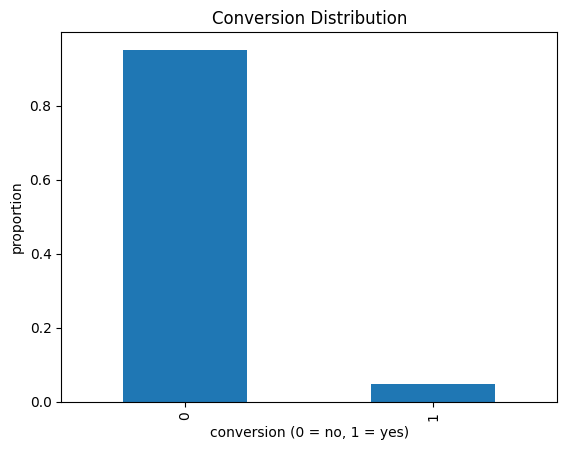

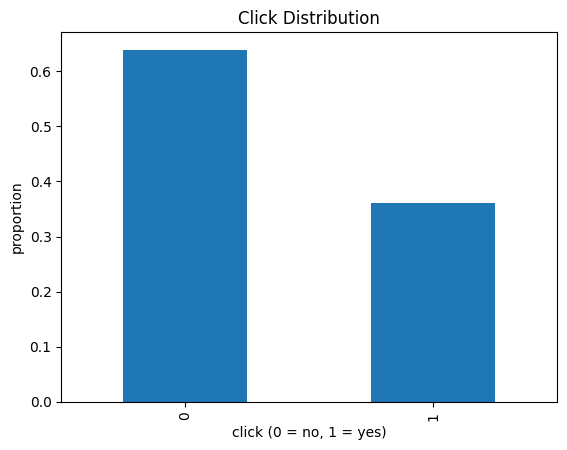

In [24]:
import matplotlib.pyplot as plt

# conversion distribution
df['conversion'].value_counts(normalize=True).plot(kind="bar")
plt.title("Conversion Distribution")
plt.xlabel("conversion (0 = no, 1 = yes)")
plt.ylabel("proportion")
plt.show()

# click distribution
df['click'].value_counts(normalize=True).plot(kind="bar")
plt.title("Click Distribution")
plt.xlabel("click (0 = no, 1 = yes)")
plt.ylabel("proportion")
plt.show()


*Time Exploration*

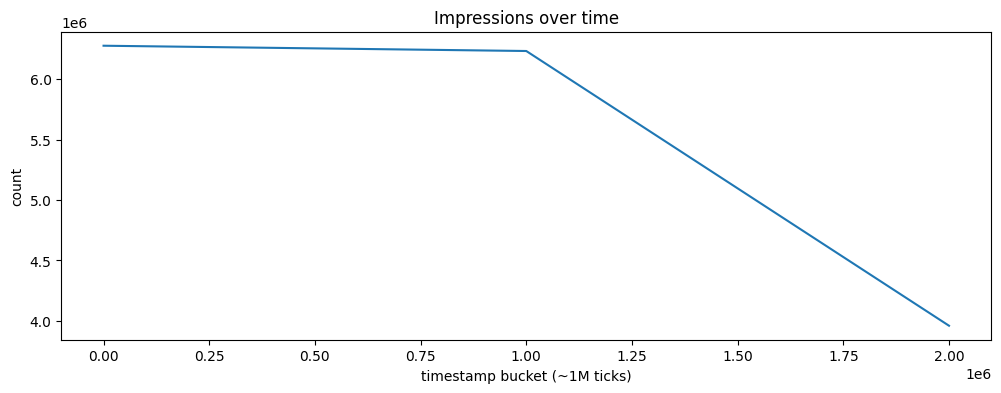

In [26]:
import pandas as pd

# impressions per million timestamps (approx window)
df['time_bucket'] = (df['timestamp'] // 1_000_000) * 1_000_000
agg = df.groupby('time_bucket').size()

agg.plot(figsize=(12,4))
plt.title("Impressions over time")
plt.xlabel("timestamp bucket (~1M ticks)")
plt.ylabel("count")
plt.show()


*cost & cpo sanity check*

In [28]:
print("Avg cost per impression:", df['cost'].mean())
print("Avg cost-per-order (cpo):", df['cpo'][df['cpo']>0].mean())


Avg cost per impression: 0.0002932557
Avg cost-per-order (cpo): 0.19642858


*categorical features (cat1…cat9)*

In [30]:
for i in range(1,10):
    col = f'cat{i}'
    print(col, ":", df[col].nunique(), "unique values")


cat1 : 9 unique values
cat2 : 70 unique values
cat3 : 1829 unique values
cat4 : 21 unique values
cat5 : 51 unique values
cat6 : 30 unique values
cat7 : 57196 unique values
cat8 : 11 unique values
cat9 : 30 unique values


*Null values*

In [36]:
df.isnull().sum().sort_values(ascending=False)


timestamp                0
uid                      0
campaign                 0
conversion               0
conversion_timestamp     0
conversion_id            0
attribution              0
click                    0
click_pos                0
click_nb                 0
cost                     0
cpo                      0
time_since_last_click    0
cat1                     0
cat2                     0
cat3                     0
cat4                     0
cat5                     0
cat6                     0
cat7                     0
cat8                     0
cat9                     0
time_bucket              0
dtype: int64

*Special placeholders* (check how often -1 appears since -1 = “no conversion”)

In [38]:
(df['conversion_timestamp'] == -1).mean()
(df['conversion_id'] == -1).mean()


np.float64(0.9510447730016474)

*Duplicate rows*

In [42]:
df.duplicated().sum()

np.int64(0)

*Outliers in numeric columns*

In [40]:
num_cols = ['click_pos','click_nb','cost','cpo','time_since_last_click']
df[num_cols].describe(percentiles=[0.01,0.05,0.95,0.99])

,click_pos,click_nb,cost,cpo,time_since_last_click
count,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07,1.646803e+07
mean,-8.312659e-01,-6.626016e-01,2.932557e-04,1.964286e-01,2.713593e+05
std,1.532221e+00,2.696254e+00,8.689672e-04,1.186382e-01,5.273109e+05
min,-1.000000e+00,-1.000000e+00,1.000000e-05,4.000000e-03,-1.000000e+00
1%,-1.000000e+00,-1.000000e+00,1.000000e-05,4.000000e-03,-1.000000e+00
5%,-1.000000e+00,-1.000000e+00,1.000000e-05,1.020588e-02,-1.000000e+00
50%,-1.000000e+00,-1.000000e+00,7.610148e-05,1.919038e-01,-1.000000e+00
95%,-1.000000e+00,-1.000000e+00,1.176471e-03,4.127726e-01,1.574577e+06
99%,3.000000e+00,8.000000e+00,3.455597e-03,5.062873e-01,2.334916e+06
max,1.730000e+02,1.740000e+02,5.834483e-02,1.016310e+00,2.592000e+06


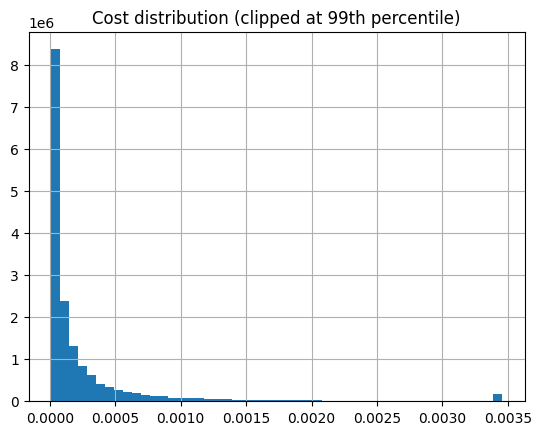

In [44]:
import matplotlib.pyplot as plt

df['cost'].clip(upper=df['cost'].quantile(0.99)).hist(bins=50)
plt.title("Cost distribution (clipped at 99th percentile)")
plt.show()


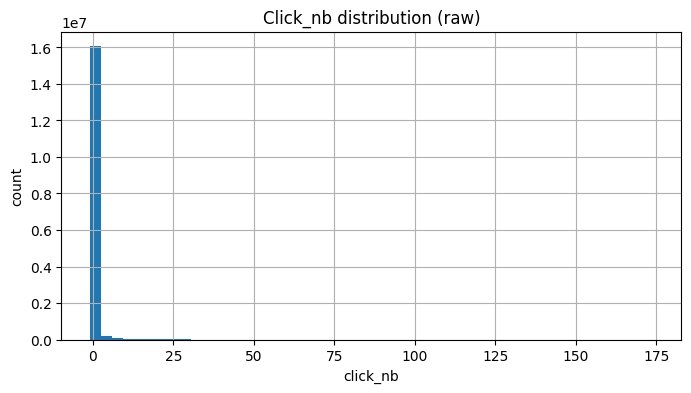

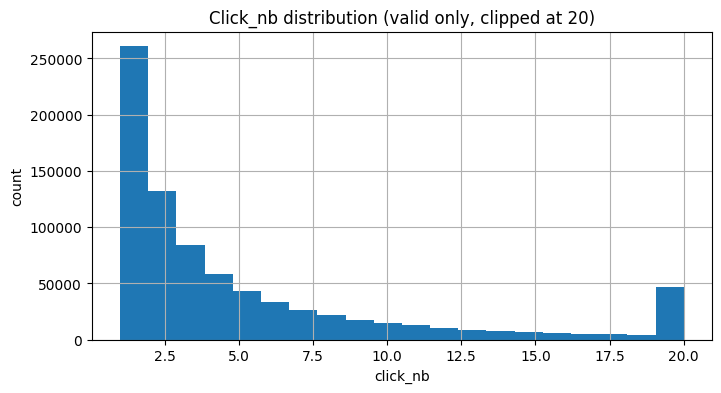

In [46]:
import matplotlib.pyplot as plt

# raw histogram
plt.figure(figsize=(8,4))
df['click_nb'].hist(bins=50)
plt.title("Click_nb distribution (raw)")
plt.xlabel("click_nb")
plt.ylabel("count")
plt.show()

# filtered (ignore -1, clip at 20)
plt.figure(figsize=(8,4))
df.loc[df['click_nb']!=-1, 'click_nb'].clip(upper=20).hist(bins=20)
plt.title("Click_nb distribution (valid only, clipped at 20)")
plt.xlabel("click_nb")
plt.ylabel("count")
plt.show()


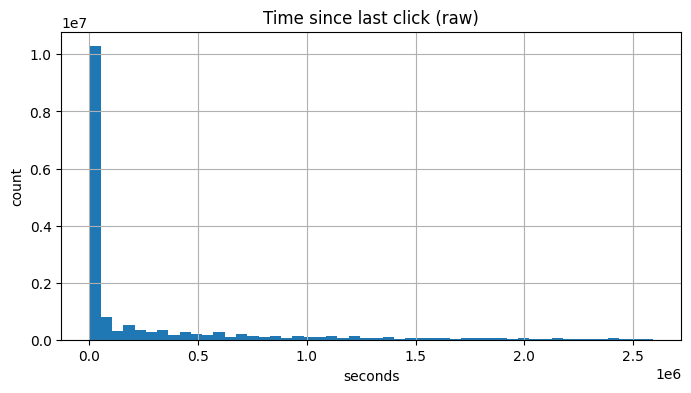

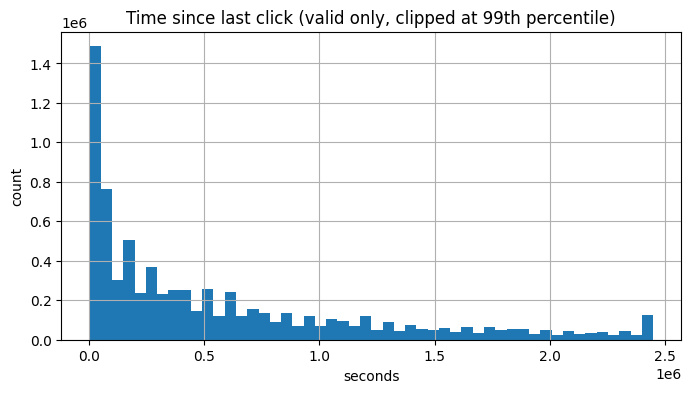

In [48]:
# raw histogram
plt.figure(figsize=(8,4))
df['time_since_last_click'].hist(bins=50)
plt.title("Time since last click (raw)")
plt.xlabel("seconds")
plt.ylabel("count")
plt.show()

# filtered (ignore -1, clip at 99th percentile)
plt.figure(figsize=(8,4))
tslc = df.loc[df['time_since_last_click']!=-1, 'time_since_last_click']
tslc.clip(upper=tslc.quantile(0.99)).hist(bins=50)
plt.title("Time since last click (valid only, clipped at 99th percentile)")
plt.xlabel("seconds")
plt.ylabel("count")
plt.show()


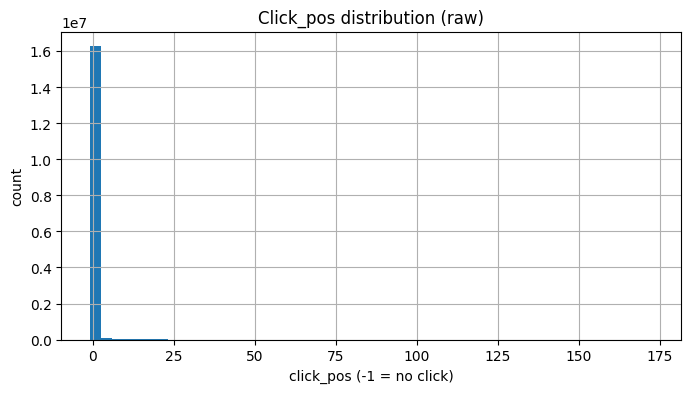

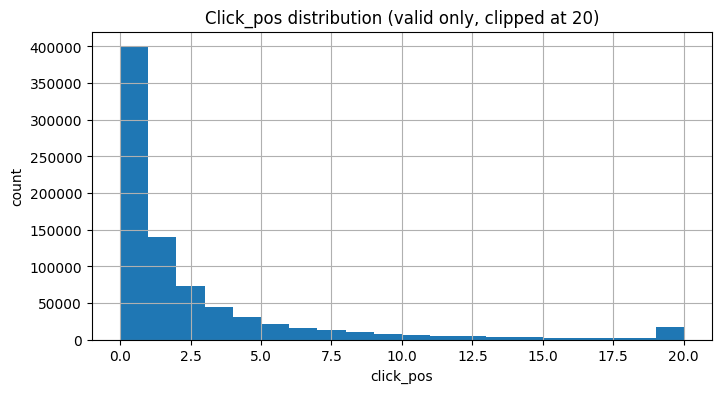

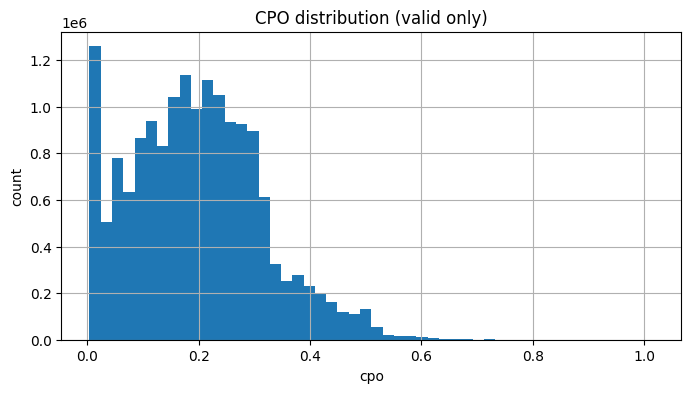

In [50]:
import matplotlib.pyplot as plt

# click_pos histogram
plt.figure(figsize=(8,4))
df['click_pos'].hist(bins=50)
plt.title("Click_pos distribution (raw)")
plt.xlabel("click_pos (-1 = no click)")
plt.ylabel("count")
plt.show()

# filtered click_pos (ignore -1, clip at 20 for readability)
plt.figure(figsize=(8,4))
df.loc[df['click_pos']!=-1, 'click_pos'].clip(upper=20).hist(bins=20)
plt.title("Click_pos distribution (valid only, clipped at 20)")
plt.xlabel("click_pos")
plt.ylabel("count")
plt.show()

# cpo histogram (ignore zeros)
plt.figure(figsize=(8,4))
df.loc[df['cpo']>0, 'cpo'].hist(bins=50)
plt.title("CPO distribution (valid only)")
plt.xlabel("cpo")
plt.ylabel("count")
plt.show()


*Marketing KPIs*

In [60]:
import numpy as np
import pandas as pd

# aggregate by campaign
agg_campaign = df.groupby('campaign').agg(
    impressions=('uid','count'),
    clicks=('click','sum'),
    conversions=('conversion','sum'),
    spend=('cost','sum')
).reset_index()

# core KPIs
agg_campaign['ctr'] = agg_campaign['clicks'] / agg_campaign['impressions']
agg_campaign['cvr'] = agg_campaign['conversions'] / agg_campaign['impressions']

# efficiency metrics
agg_campaign['cpa'] = agg_campaign['spend'] / agg_campaign['conversions'].replace(0, np.nan)
agg_campaign['cpc'] = agg_campaign['spend'] / agg_campaign['clicks'].replace(0, np.nan)

# assume each conversion = 1 unit of value (since revenue not provided)
agg_campaign['roas'] = agg_campaign['conversions'] / agg_campaign['spend'].replace(0, np.nan)

# sort campaigns by spend (largest first)
agg_campaign = agg_campaign.sort_values('spend', ascending=False)

# preview top 10 campaigns
agg_campaign.head(10)


/var/folders/d9/7q11w0fj4h37hzlh3m8w5rx80000gn/T/ipykernel_76438/2494048536.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg_campaign = df.groupby('campaign').agg(


,campaign,impressions,clicks,conversions,spend,ctr,cvr,cpa,cpc,roas
120,15398570,378464,135066,23853,155.572418,0.356879,0.063026,0.006522,0.001152,153.324094
117,15184511,256102,93175,36995,153.826553,0.363820,0.144454,0.004158,0.001651,240.498140
513,5061834,299755,85763,9861,141.244415,0.286110,0.032897,0.014324,0.001647,69.815150
6,10341182,437385,194847,45479,139.162460,0.445482,0.103979,0.003060,0.000714,326.805087
467,32368244,161056,77584,36638,138.096420,0.481721,0.227486,0.003769,0.001780,265.307384
393,29427842,239272,79009,13797,131.092468,0.330206,0.057662,0.009502,0.001659,105.246321
429,30491418,186644,72873,8234,119.051521,0.390438,0.044116,0.014459,0.001634,69.163333
365,28351001,222470,138590,23230,103.700920,0.622960,0.104419,0.004464,0.000748,224.009584
189,18975823,217646,100798,10575,82.155327,0.463128,0.048588,0.007769,0.000815,128.719590
167,17686799,381084,112964,6486,79.429840,0.296428,0.017020,0.012246,0.000703,81.656969


*Marketing KPIs with time bucket for Dashboard Purpose*

In [66]:
df['date'] = pd.to_datetime(df['timestamp'], unit='s')
df['day'] = df['date'].dt.date

agg_campaign_time = df.groupby(['campaign','day'], observed=True).agg(
    impressions=('uid','count'),
    clicks=('click','sum'),
    conversions=('conversion','sum'),
    spend=('cost','sum')
).reset_index()

agg_campaign_time['ctr'] = agg_campaign_time['clicks'] / agg_campaign_time['impressions']
agg_campaign_time['cvr'] = agg_campaign_time['conversions'] / agg_campaign_time['impressions']
agg_campaign_time['cpa'] = agg_campaign_time['spend'] / agg_campaign_time['conversions'].replace(0, np.nan)
agg_campaign_time['cpc'] = agg_campaign_time['spend'] / agg_campaign_time['clicks'].replace(0, np.nan)
agg_campaign_time['roas'] = agg_campaign_time['conversions'] / agg_campaign_time['spend'].replace(0, np.nan)


In [68]:
agg_campaign_time.head(10)

,campaign,day,impressions,clicks,conversions,spend,ctr,cvr,cpa,cpc,roas
0,10002432,1970-01-01,470,186,18,0.255327,0.395745,0.038298,0.014185,0.001373,70.497902
1,10002432,1970-01-02,465,187,22,0.321505,0.402151,0.047312,0.014614,0.001719,68.428083
2,10002432,1970-01-03,410,165,16,0.231254,0.402439,0.039024,0.014453,0.001402,69.187927
3,10002432,1970-01-04,365,145,13,0.199512,0.397260,0.035616,0.015347,0.001376,65.158962
4,10002432,1970-01-05,581,228,23,0.347455,0.392427,0.039587,0.015107,0.001524,66.195657
5,10002432,1970-01-06,498,201,21,0.275085,0.403614,0.042169,0.013099,0.001369,76.339982
6,10002432,1970-01-07,485,211,37,0.305426,0.435052,0.076289,0.008255,0.001448,121.142166
7,10002432,1970-01-08,480,186,31,0.319550,0.387500,0.064583,0.010308,0.001718,97.011565
8,10002432,1970-01-09,393,142,21,0.191483,0.361323,0.053435,0.009118,0.001348,109.670264
9,10002432,1970-01-10,313,137,14,0.174180,0.437700,0.044728,0.012441,0.001271,80.376456
